In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

In [19]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

In [20]:
data_path = r'C:\a\deep-learning-course-practice-2026\laboratory_work_2'

trainset = torchvision.datasets.CIFAR10(
    root=data_path,
    train=True,
    download=False,
    transform=train_transform
)

testset = torchvision.datasets.CIFAR10(
    root=data_path,
    train=False,
    download=False,
    transform=test_transform
)

In [21]:
batch_size = 128

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

In [23]:
print("Количество изображений для обучения:", len(trainset))
print("Количество изображений для тестирования:", len(testset))

print("Форма одного изображения:", trainset[0][0].shape)
print("Форма всех меток обучающей выборки:", torch.tensor(trainset.targets).shape)
print("Форма всех меток тестовой выборки:", torch.tensor(testset.targets).shape)

Количество изображений для обучения: 50000
Количество изображений для тестирования: 10000
Форма одного изображения: torch.Size([3, 32, 32])
Форма всех меток обучающей выборки: torch.Size([50000])
Форма всех меток тестовой выборки: torch.Size([10000])


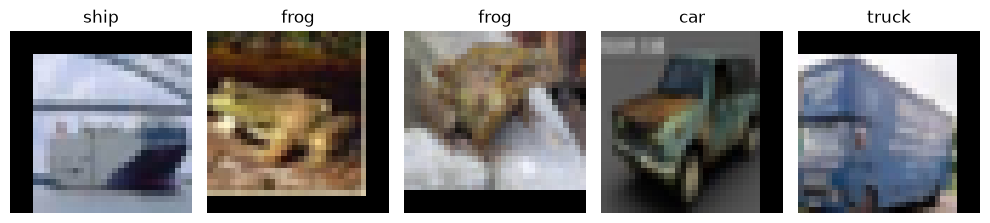

In [31]:
def show_images(images, labels):
    fig, axes = plt.subplots(1, 5, figsize=(10, 5))

    for i, ax in enumerate(axes.flat):
        img = images[i] / 2 + 0.5
        img = img.permute(1, 2, 0)

        ax.imshow(img)
        ax.set_title(classes[labels[i].item()])
        ax.axis('off')

    plt.tight_layout()
    plt.show()


images, labels = next(iter(trainloader))
show_images(images, labels)

In [39]:
class CIFAR10_CNN(nn.Module):
    def __init__(self):
        super(CIFAR10_CNN, self).__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2, 2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2, 2)
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)

        x = self.classifier(x)

        return x

In [40]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)

model = CIFAR10_CNN().to(device)
print(model)

Устройство: cuda
CIFAR10_CNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil

In [41]:
loss_function = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

In [43]:
num_epochs = 40

train_losses = []
train_accuracies = []

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in trainloader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total
    epoch_error = 100 - epoch_accuracy

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Эпоха {epoch + 1}/{num_epochs}  "
        f"Loss: {epoch_loss:.4f}  "
        f"Accuracy: {epoch_accuracy:.2f}%  "
        f"Error: {epoch_error:.2f}%"
    )

print("Обучение завершено!")

Эпоха 1/40  Loss: 1.4037  Accuracy: 48.02%  Error: 51.98%
Эпоха 2/40  Loss: 0.9967  Accuracy: 64.27%  Error: 35.73%
Эпоха 3/40  Loss: 0.8374  Accuracy: 70.64%  Error: 29.36%
Эпоха 4/40  Loss: 0.7340  Accuracy: 74.63%  Error: 25.37%
Эпоха 5/40  Loss: 0.6689  Accuracy: 76.86%  Error: 23.14%
Эпоха 6/40  Loss: 0.6188  Accuracy: 78.71%  Error: 21.29%
Эпоха 7/40  Loss: 0.5758  Accuracy: 80.16%  Error: 19.84%
Эпоха 8/40  Loss: 0.5419  Accuracy: 81.41%  Error: 18.59%
Эпоха 9/40  Loss: 0.5143  Accuracy: 82.59%  Error: 17.41%
Эпоха 10/40  Loss: 0.4900  Accuracy: 83.34%  Error: 16.66%
Эпоха 11/40  Loss: 0.4693  Accuracy: 84.01%  Error: 15.99%
Эпоха 12/40  Loss: 0.4474  Accuracy: 84.68%  Error: 15.32%
Эпоха 13/40  Loss: 0.4348  Accuracy: 85.18%  Error: 14.82%
Эпоха 14/40  Loss: 0.4197  Accuracy: 85.62%  Error: 14.38%
Эпоха 15/40  Loss: 0.4093  Accuracy: 86.02%  Error: 13.98%
Эпоха 16/40  Loss: 0.3899  Accuracy: 86.83%  Error: 13.17%
Эпоха 17/40  Loss: 0.3831  Accuracy: 86.96%  Error: 13.04%
Эпоха 

In [45]:
model.eval()

test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for images, labels in testloader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = loss_function(outputs, labels)

        test_loss += loss.item() * labels.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_loss = test_loss / total
test_accuracy = 100 * correct / total
test_error = 100 - test_accuracy

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Test Error: {test_error:.2f}%")

Test Loss: 0.3967
Test Accuracy: 87.23%
Test Error: 12.77%


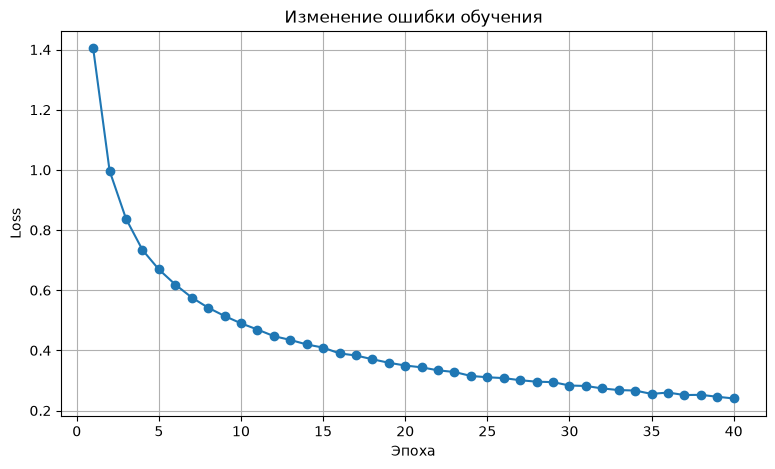

In [50]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker='o')
plt.title('Изменение ошибки обучения')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.grid(True)

plt.show()